# Vision Agents with smolagents


This notebook is part of the [Hugging Face Agents Course](https://www.hf.co/learn/agents-course), a free Course from beginner to expert, where you learn to build Agents.

![Agents course share](https://huggingface.co/datasets/agents-course/course-images/resolve/main/en/communication/share.png)

> **Colab adaptation:** The original visual task is run with GroqCloud and Qwen, which accepts image inputs. Enable `GROQ_API_KEY` in Colab Secrets. The dynamic browser example remains a separate Python script.

> **Validation status.** Preserved outputs are historical evidence from the supplied notebook. Local checks may add their own evidence. Consult the accompanying validation report for the checks run on this revision and the exercises still pending authenticated Colab verification.

## Let's install the dependencies and configure Groq access

If you haven't installed `smolagents` yet, you can do so by running the following command:

In [2]:
%pip install -q "smolagents[openai,toolkit]==1.26.0" "requests==2.32.4" pillow


The original course logs in to the Hugging Face Hub for inference. This version uses the existing Colab secret `GROQ_API_KEY` and the OpenAI-compatible Groq endpoint.

Qwen accepts the two course images in one multimodal request. The notebook saves a verified local copy of each original image for subsequent runs. The agent run requires both images. Dynamic screenshots are covered in notebook 09.


In [ ]:
import os
from time import monotonic, sleep
from uuid import uuid4

from openai import APIConnectionError, APIStatusError, OpenAI, RateLimitError
from smolagents import OpenAIModel, ToolCallingAgent
from smolagents.models import ChatMessageToolCall, ChatMessageToolCallFunction

def read_secret(name):
    value = os.getenv(name)
    if value:
        return value
    try:
        from google.colab import userdata
    except ImportError:
        return None
    try:
        return userdata.get(name)
    except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
        return None

GROQ_API_KEY = read_secret("GROQ_API_KEY")
GROQ_BASE = "https://api.groq.com/openai/v1"
client = (OpenAI(api_key=GROQ_API_KEY, base_url=GROQ_BASE, timeout=20, max_retries=0)
          if GROQ_API_KEY else None)
MODEL_ID = os.getenv("GROQ_MODEL_ID", "qwen/qwen3.8-27b")
VISION_MODEL_ID = os.getenv("GROQ_VISION_MODEL_ID", "qwen/qwen3.8-27b")
TEXT_MODELS = (MODEL_ID, "openai/gpt-oss-20b", "qwen/qwen3.8-27b")
MODEL_REQUEST_LIMIT = int(os.getenv("GROQ_MAX_REQUESTS", "6"))
model_requests = 0
last_model_request = 0.0

class GroqAgentModel(OpenAIModel):
    """Use Groq's native tool validation and accept genuine text final answers."""
    def _prepare_completion_kwargs(self, *args, **kwargs):
        policy = getattr(self, "tool_policy", None)
        forced = policy() if policy and kwargs.get("tools_to_call_from") else None
        kwargs["tool_choice"] = (
            {"type": "function", "function": {"name": forced}} if forced else "auto"
        )
        request = super()._prepare_completion_kwargs(*args, **kwargs)
        request.pop("stop", None)
        for message in request["messages"]:
            message.pop("name", None)
        if request.get("tools"):
            request["parallel_tool_calls"] = False
        # Keep tool calls and their observations together; do not truncate message history.
        request.setdefault("max_completion_tokens", 2000)
        return request

    def generate(self, messages, *args, tools_to_call_from=None, **kwargs):
        global model_requests, last_model_request
        original_model = self.model_id
        original_options = self.kwargs.copy()
        options = (original_model,) if original_model == VISION_MODEL_ID else TEXT_MODELS
        deadline = monotonic() + 150
        try:
            for attempt in range(2):
                if model_requests >= MODEL_REQUEST_LIMIT or monotonic() >= deadline:
                    raise RuntimeError("Model request budget exhausted.")
                self.model_id = options[min(attempt, len(options) - 1)]
                self.kwargs.pop("reasoning_effort", None)
                if self.model_id.startswith("openai/gpt-oss"):
                    self.kwargs["reasoning_effort"] = "low"
                elif self.model_id == VISION_MODEL_ID:
                    self.kwargs["reasoning_effort"] = "none"
                sleep(max(0, 30 - (monotonic() - last_model_request)))
                last_model_request = monotonic()
                model_requests += 1
                try:
                    reply = super().generate(
                        messages, *args, tools_to_call_from=tools_to_call_from, **kwargs
                    )
                except (APIStatusError, APIConnectionError) as exc:
                    status = getattr(exc, "status_code", 0) or 0
                    code = getattr(exc, "code", None)
                    recoverable = (status in (404, 429) or status >= 500 or status == 0
                                   or code in ("tool_use_failed", "model_decommissioned"))
                    if attempt or not recoverable:
                        raise RuntimeError(
                            f"Groq request failed for {self.model_id} (HTTP {status or 'connection'}, "
                            f"{code or type(exc).__name__})."
                        ) from None
                    if isinstance(exc, RateLimitError):
                        try:
                            delay = float(exc.response.headers.get("retry-after", "2"))
                        except ValueError:
                            delay = 2
                        if delay > 60:
                            raise RuntimeError(
                                f"Groq vision quota is limited; retry after {delay:g} seconds."
                            ) from None
                        sleep(max(1, min(delay, 60)))
                    print("Groq request interrupted; making one bounded retry.")
                    continue
                names = {tool.name for tool in tools_to_call_from or ()}
                text = reply.content
                if ("final_answer" in names and not reply.tool_calls
                        and isinstance(text, str) and text.strip()):
                    # smolagents expects a final_answer action. Carry the real text into
                    # that action locally without changing any external tool observations.
                    # Normalize only an explicit final-answer envelope, never arbitrary tool calls.
                    import json
                    try:
                        envelope = json.loads(text.strip())
                        if isinstance(envelope, dict) and envelope.get("name") == "final_answer":
                            answer = envelope.get("arguments", {}).get("answer")
                            if isinstance(answer, str):
                                text = answer
                    except (ValueError, TypeError):
                        pass
                    reply.tool_calls = [ChatMessageToolCall(
                        function=ChatMessageToolCallFunction(
                            name="final_answer", arguments={"answer": text.strip()}),
                        id=f"local_final_{uuid4().hex}", type="function",
                    )]
                if attempt:
                    print("Groq retry completed with", self.model_id)
                return reply
        finally:
            self.model_id = original_model
            self.kwargs = original_options

def make_model(max_tokens=2000, model_id=MODEL_ID):
    if not client:
        raise RuntimeError("Enable notebook access to GROQ_API_KEY in Colab Secrets.")
    return GroqAgentModel(
        model_id=model_id, api_base=GROQ_BASE, api_key=GROQ_API_KEY,
        temperature=0.2, max_completion_tokens=max_tokens, retry=False,
        client_kwargs={"timeout": 20, "max_retries": 0},
    )

def completed_tools(agent):
    return {
        call.name for step in agent.memory.steps
        if getattr(step, "error", None) is None
        for call in (getattr(step, "tool_calls", None) or ())
    }

def run_checked(agent, prompt, required=(), ordered=(), **kwargs):
    global model_requests
    if agent.model is None:
        raise RuntimeError("Configure GROQ_API_KEY in environment variables or Colab Secrets before agent inference.")
    # Each top-level exercise has its own budget, shared with its managed agents.
    model_requests = 0
    def next_tool():
        completed = completed_tools(agent)
        return next((name for name in ordered if name not in completed), None)

    agent.model.tool_policy = next_tool
    try:
        result = agent.run(prompt, return_full_result=True, **kwargs)
    finally:
        agent.model.tool_policy = None
    missing = set(required) - completed_tools(agent)
    if result.state != "success" or missing or not result.output:
        raise RuntimeError(f"Agent exercise incomplete: {result.state}; missing tools: {sorted(missing)}.")
    if result.token_usage:
        print("Agent tokens:", result.token_usage)
    return result.output

# Keep local tool checks available even when Groq credentials are unavailable.
model = make_model() if client else None


## Providing Images at the Start of the Agent's Execution

In this approach, images are passed to the agent at the start and stored as `task_images` alongside the task prompt. The agent then processes these images throughout its execution.  

Consider the case where Alfred wants to verify the identities of the superheroes attending the party. He already has a dataset of images from previous parties with the names of the guests. Given a new visitor's image, the agent can compare it with the existing dataset and make a decision about letting them in.  

In this case, a guest is trying to enter, and Alfred suspects that this visitor might be The Joker impersonating Wonder Woman. Alfred needs to verify their identity to prevent anyone unwanted from entering.  

Let’s build the example. First, the images are loaded. In this case, we use images from Wikipedia to keep the example minimal, but imagine the possible use-cases!

Image 1: downloaded original, 640 × 832 | https://upload.wikimedia.org/wikipedia/commons/e/e8/The_Joker_at_Wax_Museum_Plus.jpg


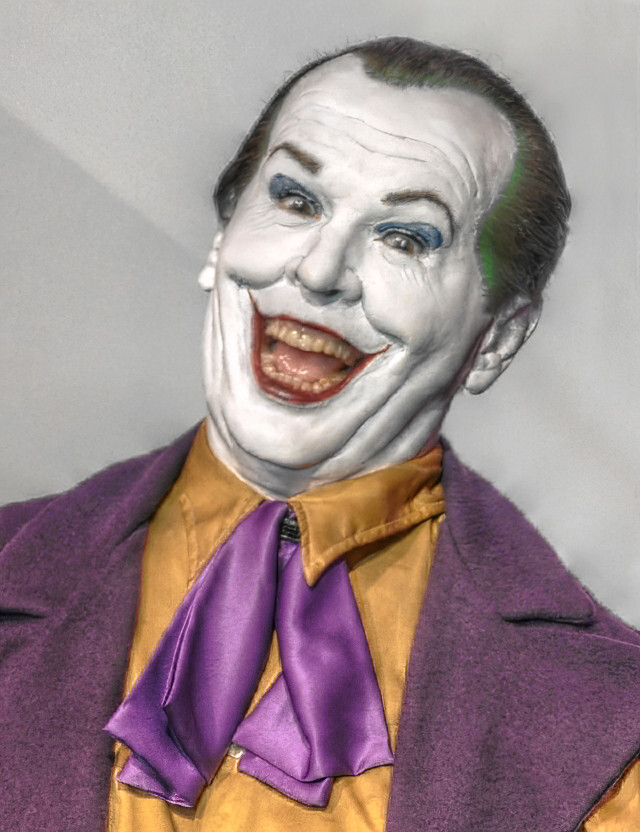

Image 2: downloaded original, 250 × 315 | https://upload.wikimedia.org/wikipedia/en/9/98/Joker_%28DC_Comics_character%29.jpg


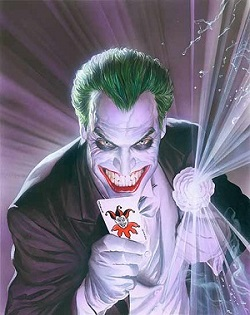

In [2]:
from io import BytesIO
from pathlib import Path

import requests
from IPython.display import Image as NotebookImage, display
from PIL import Image
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

image_urls = [
    "https://upload.wikimedia.org/wikipedia/commons/e/e8/The_Joker_at_Wax_Museum_Plus.jpg",
    "https://upload.wikimedia.org/wikipedia/en/9/98/Joker_%28DC_Comics_character%29.jpg",
]
cache_dir = Path(".course_joker_assets")
cache_dir.mkdir(exist_ok=True)
max_image_bytes = 5 * 1024 * 1024

def decode_image(data):
    with Image.open(BytesIO(data)) as image:
        photo = image.convert("RGB")
    photo.thumbnail((1000, 1000))
    return photo

def fetch_course_image(session, url, position):
    cache_path = cache_dir / f"original_{position}.jpg"
    if cache_path.is_file() and cache_path.stat().st_size <= max_image_bytes:
        try:
            return decode_image(cache_path.read_bytes()), "cached original"
        except (OSError, ValueError):
            cache_path.unlink()
    with session.get(url, timeout=(5, 12), stream=True) as response:
        response.raise_for_status()
        data = bytearray()
        for chunk in response.iter_content(chunk_size=65536):
            data.extend(chunk)
            if len(data) > max_image_bytes:
                raise ValueError("Original image exceeds the download limit.")
    photo = decode_image(data)
    temporary = cache_path.with_suffix(".tmp")
    temporary.write_bytes(data)
    temporary.replace(cache_path)
    return photo, "downloaded original"

images = []
with requests.Session() as session:
    session.headers["User-Agent"] = "HF-Agents-Course-Colab/1.0 (educational notebook; public image retrieval)"
    # Bound retries and avoid long Retry-After waits in an interactive notebook.
    session.mount("https://", HTTPAdapter(max_retries=Retry(
        total=1, status_forcelist=(429, 500, 502, 503, 504),
        allowed_methods={"GET"}, respect_retry_after_header=False, backoff_factor=0,
    )))
    for position, url in enumerate(image_urls, start=1):
        try:
            image, origin = fetch_course_image(session, url, position)
        except (requests.RequestException, OSError, ValueError) as exc:
            status = getattr(getattr(exc, "response", None), "status_code", None)
            print(f"Image {position} unavailable: {status or type(exc).__name__} | {url}")
            continue
        images.append(image)
        print(f"Image {position}: {origin}, {image.width} × {image.height} | {url}")
        png = BytesIO()
        image.save(png, format="PNG")
        display(NotebookImage(data=png.getvalue()))


Now that we have the images, the agent will tell us wether the guests is actually a superhero (Wonder Woman) or a villian (The Joker).

In [ ]:
if len(images) != len(image_urls):
    raise RuntimeError("Both original course images must load before vision inference.")
print(f"Ready: {len(images)} original course images.")

# Optional public Space adapter; the primary exercise below uses native vision inference.
# Instantiate this adapter explicitly only when the service is available.
from smolagents import Model
from smolagents.models import ChatMessage
from gradio_client import Client, handle_file
class PublicSpaceVisionModel(Model):
    def __init__(self, image_inputs):
        super().__init__()
        self.model_id = "HuggingFaceTB/SmolVLM-256M-Demo"
        self.image_inputs = image_inputs
        self.calls = 0
    def generate(self, messages, stop_sequences=None, **kwargs):
        if self.calls:
            raise RuntimeError("Free vision request budget exhausted; inspect the first failure.")
        self.calls += 1
        parts = []
        for message in messages:
            if str(message.get("role", "")) in ("user", "MessageRole.USER"):
                content = message.get("content", [])
                if isinstance(content, str): parts.append(content)
                else: parts.extend(p["text"] for p in content if p.get("type") == "text")
        paths=[]
        for index, image in enumerate(self.image_inputs):
            path=Path(f"fallback_input_{index+1}.jpg")
            image.convert("RGB").save(path,quality=85)
            paths.append(handle_file(str(path)))
        service=Client(self.model_id,httpx_kwargs={"timeout":60})
        job=service.submit({"text":"\n".join(parts)[-2500:],"files":paths},api_name="/chat")
        try:
            answer=job.result(timeout=90)
        except TimeoutError:
            job.cancel()
            raise
        if not isinstance(answer,str) or not answer.strip():
            raise RuntimeError(f"Unexpected free vision response type: {type(answer).__name__}")
        print("Inference provider: public SmolVLM Space (free fallback)")
        return ChatMessage(role="assistant",content=answer,tool_calls=[ChatMessageToolCall(
            id="space_vision_final",type="function",
            function=ChatMessageToolCallFunction(name="final_answer",arguments={"answer":answer}))])


Ready: 2 original course images.


In [ ]:
response = None
if len(images) != len(image_urls):
    raise RuntimeError("Vision inference requires both original images.")
# Image-only inference does not need function/tool calling support from the vision model.
prompt = "Compare the supplied fictional comic character images. Describe only visible costume, hair and makeup. Conclude Joker or Wonder Woman for each depiction, with at most 100 words total."
inference_images = [im.copy() for im in images]
for im in inference_images:
    im.thumbnail((320, 320))
vision_model = make_model(max_tokens=1600, model_id=VISION_MODEL_ID)
message = {"role": "user", "content": [{"type": "text", "text": prompt}] +
           [{"type": "image", "image": im} for im in inference_images]}
reply = vision_model.generate([message])
if not isinstance(reply.content, str) or not reply.content.strip():
    raise RuntimeError("The vision provider did not return a non-empty answer.")
response = reply.content.strip()
print(response)


In [ ]:
if globals().get("response"):
    print(response)
else:
    print("No vision answer is available yet. Configure the provider and run the inference cell first.")


In this case, the output reveals that the person is impersonating someone else, so we can prevent The Joker from entering the party!

This conclusion describes the course scenario; use the new two-image output above as the validation evidence.


## Providing Images with Dynamic Retrieval

This examples is provided as a `.py` file since it needs to be run locally since it'll browse the web. Go to the [Hugging Face Agents Course](https://www.hf.co/learn/agents-course) for more details.

## Gemini continuation — visual inference
The two images below are compressed copies of the exact images downloaded by the earlier notebook. This direct multimodal call answers the original visual question without repeating downloads. It is not a full smolagents agent run.

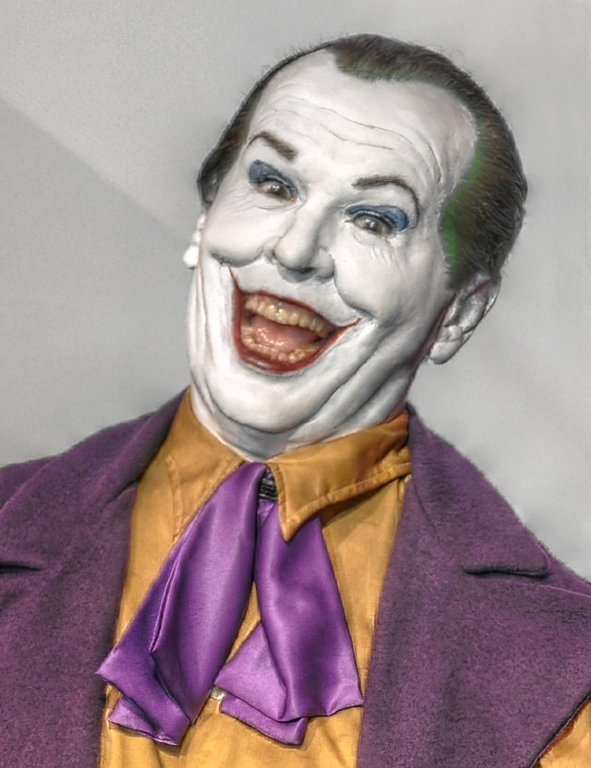

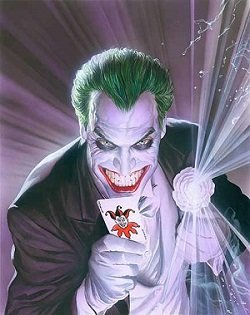

Here is a comparison of the two fictional character depictions:

**First Depiction:**
* **Clothing:** Wears a purple suit jacket over a gold/yellow collared shirt with a matching purple cravat.
* **Hair:** Slicked-back, dark hair tinted with green on the sides.
* **Makeup:** Thick white face paint, blue eyeshadow, and wide red lipstick extending into an exaggerated, smiling grin.

**Second Depiction:**
* **Clothing:** Wears a dark suit jacket, a white collared shirt, and a white lapel flower spraying water/light, holding a Joker playing card.
* **Hair:** Vibrant, tousled green hair.
* **Makeup:** White-painted skin, dark eye makeup, and bright red lipstick forming a wide, menacing smile.

**Conclusion:**
Both depicted fictional characters represent the **Joker**.
Gemini usage: CompletionUsage(completion_tokens=181, prompt_tokens=2224, total_tokens=2405, completion_tokens_details=None, prompt_tokens_details=None)


In [1]:
import os
from openai import OpenAI
from IPython.display import display

def gemini_client():
    key = os.environ.get('AGENTS_GEMINI_KEY')
    if not key:
        from google.colab import userdata
        key = userdata.get('GEMINI_API_KEY')
    return OpenAI(api_key=key,base_url='https://generativelanguage.googleapis.com/v1beta/openai/',timeout=60,max_retries=0)

GEMINI_MODEL = 'gemini-3.5-flash-lite'

# Compressed copies of the actual images saved in the previous execution.
import base64
from io import BytesIO
from PIL import Image
saved_images = ['...']
for encoded in saved_images:
    display(Image.open(BytesIO(base64.b64decode(encoded))))
parts = [{'type':'text','text':'Compare the two supplied fictional comic character depictions. For each, describe visible clothing, hair and makeup. Conclude whether the depicted fictional character represents Joker or Wonder Woman. At most 100 words. Do not identify any real person.'}]
parts += [{'type':'image_url','image_url':{'url':'data:image/jpeg;base64,'+encoded}} for encoded in saved_images]
client=gemini_client()
answer=client.chat.completions.create(model=GEMINI_MODEL,messages=[{'role':'user','content':parts}],max_tokens=1200)
response=answer.choices[0].message.content
if not response or not response.strip(): raise RuntimeError('Empty Gemini vision response')
print(response)
print('Gemini usage:',answer.usage)